In [1]:
import numpy as np
import pandas as pd
import time

In [35]:
df = pd.read_csv('./Social_Network_Ads.csv')

In [36]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [37]:
df = df[['Age','EstimatedSalary','Purchased']]

In [38]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [39]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [40]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [41]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [42]:
X_scaled.shape

(400, 2)

In [43]:
#from sklearn.model_selection import train_test_split
#X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [44]:
#X_train.shape

In [45]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [46]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

# Stochastic Gradient Descent (SGD)

In [48]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
start = time.time()
history = model.fit(X_scaled,y,epochs=100,batch_size=1,validation_split=0.2)
print(time.time() - start)

Epoch 1/100


320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7125 - loss: 0.5352 - val_accuracy: 0.3625 - val_loss: 0.6604
Epoch 2/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7125 - loss: 0.3890 - val_accuracy: 0.3625 - val_loss: 0.6048
Epoch 3/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7906 - loss: 0.3537 - val_accuracy: 0.6500 - val_loss: 0.5733
Epoch 4/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8594 - loss: 0.3393 - val_accuracy: 0.7875 - val_loss: 0.5453
Epoch 5/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8625 - loss: 0.3309 - val_accuracy: 0.8625 - val_loss: 0.5209
Epoch 6/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8687 - loss: 0.3236 - val_accuracy: 0.9000 - val_loss: 0.4932
Epoch 7/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8687 - loss: 0.3197 - val_accuracy: 0.9000 - val_loss: 0.4766
Epoch 8/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8625 - loss: 0.3128 - val_accuracy: 0.9250

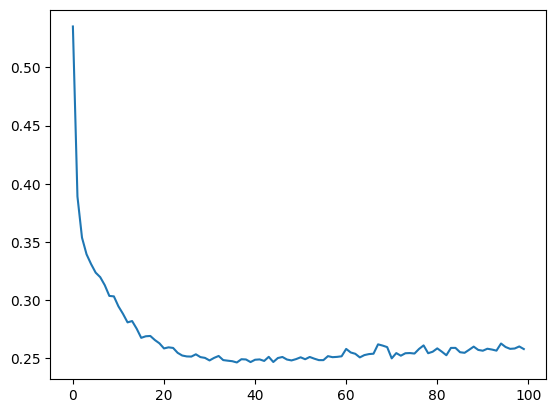

In [49]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])

In [50]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

# Batch Gradient Descent

In [51]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
start = time.time()
history = model.fit(X_scaled,y,epochs=100,batch_size=400,validation_split=0.2)
print(time.time() - start)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 594ms/step - accuracy: 0.4250 - loss: 0.7460 - val_accuracy: 0.4875 - val_loss: 0.7676
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.4781 - loss: 0.7380 - val_accuracy: 0.5000 - val_loss: 0.7649
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5219 - loss: 0.7323 - val_accuracy: 0.4500 - val_loss: 0.7628
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5562 - loss: 0.7275 - val_accuracy: 0.3625 - val_loss: 0.7610
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5750 - loss: 0.7233 - val_accuracy: 0.3750 - val_loss: 0.7593
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5875 - loss: 0.7195 - val_accuracy: 0.3750 - val_loss: 0.7578
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.6250 - loss: 0.7160 - val_accuracy: 0.3500 - val_loss: 0.7564
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.6531 - loss: 0.7127 - val_accuracy: 0.3500 - val_loss

### <span style="color:orange"> You can see for the same number of epochs, Batch Gradient Descent is faster than Stochastic Gradient Descent. This is because Batch Gradient Descent updates the parameters once per epoch, while Stochastic Gradient Descent updates the parameters for each training example, resulting in more updates and thus taking more time.</span>

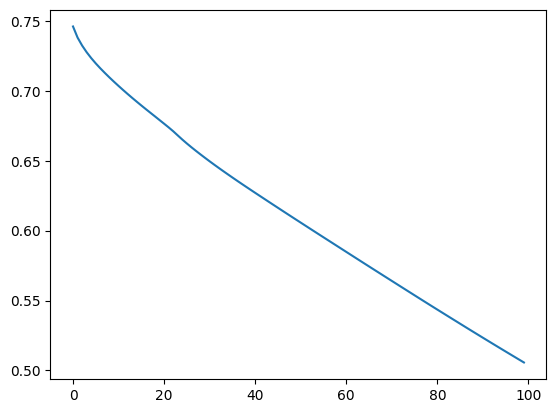

In [52]:
plt.plot(history.history['loss'])